In [4]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.5 MB ? eta -:--:--
   ---- ----------------------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

df = pd.read_csv("../data/customers_clean_v2.csv")

#Train the leak-free model

In [8]:
X = df.select_dtypes("number").drop(columns=["is_churn", "total_secs", "active_days", "unique_songs"], errors="ignore")
y = df["is_churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = lgb.LGBMClassifier(random_state=42, verbose=-1)
model.fit(X_train, y_train)
print("AUC:", round(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]), 3))

AUC: 0.871


#Score each test customer for risk and value.

In [9]:
test = df.loc[X_test.index].copy()
test["risk"] = model.predict_proba(X_test)[:, 1]

test["monthly_value"] = (test["total_paid"] / test["num_payments"]) / test["plan_days"] * 30
test["monthly_value"] = test["monthly_value"].replace([np.inf, -np.inf], np.nan)
test["monthly_value"] = test["monthly_value"].fillna(test["monthly_value"].median())
test["monthly_value"] = test["monthly_value"].clip(upper=test["monthly_value"].quantile(0.99))

#Expected gain per customer.

In [10]:
offer_cost = 50      # NT$ per retention offer (e.g. a discounted month)
save_rate = 0.077    # offer success rate, from the 7.7-point lift in 05_uplift

test["expected_gain"] = test["risk"] * save_rate * test["monthly_value"] * 12 - offer_cost

In [11]:
budget = 100000
n_offers = budget // offer_cost

smart = test.sort_values("expected_gain", ascending=False).head(n_offers)
random_pick = test.sample(n_offers, random_state=42)

for name, group in [("Model targeting", smart), ("Random targeting", random_pick)]:
    saved = (group["risk"] * save_rate * group["monthly_value"] * 12).sum()
    print(name, "| revenue saved: NT$", round(saved), "| net profit: NT$", round(saved - budget))

Model targeting | revenue saved: NT$ 226780 | net profit: NT$ 126780
Random targeting | revenue saved: NT$ 22588 | net profit: NT$ -77412


#best number of offers.

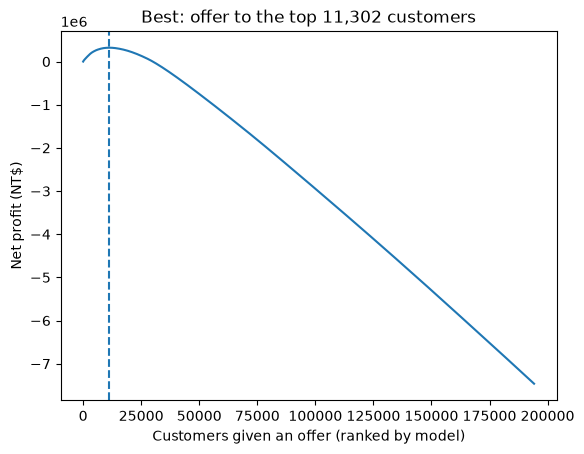

Best number of offers: 11302 | max net profit: NT$ 321701


In [12]:
profit = test.sort_values("expected_gain", ascending=False)["expected_gain"].cumsum().values
best = profit.argmax() + 1

plt.plot(range(1, len(profit) + 1), profit)
plt.axvline(best, linestyle="--")
plt.xlabel("Customers given an offer (ranked by model)")
plt.ylabel("Net profit (NT$)")
plt.title(f"Best: offer to the top {best:,} customers")
plt.show()

print("Best number of offers:", best, "| max net profit: NT$", round(profit.max()))

## Findings

- I kept the leak-free model (AUC 0.871) and used it to rank customers by expected profit from a retention offer.
- With a NT$100,000 budget, targeting by my model saved about NT$226,780 (net profit NT$126,780), while random targeting lost NT$77,412. That's about 10 times more revenue saved.
- The best number of customers to target is the top 11,302, giving a maximum net profit of about NT$321,701.
- These numbers rest on two assumptions: an offer costs NT$50, and it keeps 7.7% of at-risk customers (the lift I measured in 05_uplift).